# Bottleneck size calculation

In [1]:
#import packages and plot set-up
import numpy as np, pandas as pd
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.lines import Line2D


import seaborn as sns

#plot settings
sns.set_theme(style="white", font="Arial")

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

# Optional: increase font size globally
plt.rcParams['font.size'] = 12
sns.set_context({'font.size': 10.0, 'axes.labelsize': 12, 'axes.titlesize': 14,
                 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
                 'legend.title_fontsize': None, 'axes.linewidth': 0.8, 'grid.linewidth': 0.8,
                 'lines.linewidth': 1.5, 'lines.markersize': 6.0, 'patch.linewidth': 1.0,
                 'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.minor.width': 0.3,
                 'ytick.minor.width': 0.3, 'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
                 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,})
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True

In [2]:
variant_frequencies = [0.001, 0.01, 0.1]

bottleneck_sizes = [1,2,3,4,5,6,7,8,9,10,20,30,40,50,60,70,80,90,100,200,300,400,500,600,700,800,900,1000, 
                    2000,3000,4000,5000,6000,7000,8000,9000,10000]


In [3]:
#starting with set population size of 1e7 
population_size = int(1e5)

n_iter = 10000
randgen = np.random.default_rng(seed=450)

results = []
for vf in variant_frequencies:
    n_mutated = int(round(vf * population_size))
    n_wildtype = population_size - n_mutated

    for bottleneck in bottleneck_sizes:
        hits = randgen.hypergeometric(ngood=n_mutated, nbad=n_wildtype, nsample=bottleneck,size=n_iter)
        prob_of_loss = (hits == 0).mean()
        results.append([vf, bottleneck, prob_of_loss])
        


probability_of_loss = pd.DataFrame.from_records(results,columns=["variant frequency", "bottleneck size", "probability of loss"])

/var/folders/3r/pf10m1dj4lg0cf02535yqnlm0000gn/T/ipykernel_96477/3453594274.py:13: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 11e3)


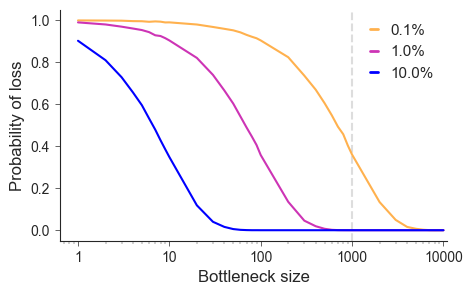

In [4]:
fig, ax = plt.subplots(1,1, figsize=(5, 3))

color_list = [ "#ffb14e", "#cd34b5", "#0000ff" ]

legend_elements = []
for vf, col in zip(variant_frequencies, color_list):
    df = probability_of_loss[probability_of_loss["variant frequency"]==vf]
    legend_elements.append(Line2D([0], [0], color=col, label=f"{vf*100}%", linewidth=2,  ))
    
    ax.semilogx(df["bottleneck size"], df["probability of loss"], color=col)
    
ax.axvline(1000, color="#DDDDDD", ls="--", zorder=-20)
ax.set_xlim(0, 11e3)
ax.set_ylim(-.05,1.05)
ax.set_ylabel("Probability of loss")
ax.set_xlabel("Bottleneck size")
ax.set_xticks([1,10,100, 1000, 10000])
ax.set_xticklabels([1,10,100, 1000, 10000])

ax.spines[['top','right',]].set_visible(False)
leg = ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1, 1), ncols =1, fontsize=11, handlelength=0.5, edgecolor=None, frameon=False, 
                                columnspacing=0.5)


fig.savefig("../figures/figS1_bottleneck_size.svg", dpi=300,bbox_inches='tight')
fig.savefig("../figures/figS1_bottleneck_size.png", dpi=300,bbox_inches='tight') 